# Module 8 Assignment - Time Series Forecasting Model Starter Code
---
<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>Module_Eight_Assignment_Time_Series_Forecasting_Model_Starter_Code.ipynb</b> file to complete the assignment. Then, you may create your own .ipynb file or .py file to complete this assignment.
<br><br>
<b>When Finished:</b> When you have completed your work, submit the work as a <b>.ipynb file</b> or a <b>.py</b> file to BrightSpace.
</div>

<div class="alert alert-block alert-info" style="color:black;">
Look for the header <b>Start of Rubric Graded Items</b> to work on your assignment if you are going to submit this file as the work submission.
</div>

<div class="alert alert-block alert-danger" style="color:black;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
<b>Example messages:</b>
    <ul>
        <li>Could not find cuda drivers on your machine, GPU will not be used.</li>
        <li>Please check linkage and avoid linking the same target more than once.</li>
        <li>E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)</li>
        <li>Allocation of ######## exceeds 10% of free system memory</li>
    </ul>
</div>

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

2026-11-13 00:04:12.808896: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/ubuntu/.local/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


TensorFlow version: 2.20.0


## Start of Graded Rubric Items

### TODO: Apply Preprocessing techniques for time-series forecasting

In [2]:
# Load Jena Climate dataset (temperature time series)

df = pd.read_csv('jena_climate_2009_2016.csv')
print(df.head())

# We will forecast temperature in degrees Celsius: column 'T (degC)'
target_col = "T (degC)"
temperature = df[target_col].values.astype("float32")

# The data is recorded every 10 minutes

# TODO: Downsample to hourly by taking every 6th measurement.
temperature = temperature[::6]

print("Downsampled length (hourly):", len(temperature))


             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0       1307.75      1.03        

In [3]:
# Normalize and create train/val/test splits

# TODO: Experiment with split ratios
n = len(temperature)
train_split = int(0.7 * n)
val_split = int(0.85 * n)

train_series = temperature[:train_split]
val_series   = temperature[train_split:val_split]
test_series  = temperature[val_split:]

# Normalize based on training data statistics
mean = train_series.mean()
std  = train_series.std()

train_norm = (train_series - mean) / std
val_norm   = (val_series   - mean) / std
test_norm  = (test_series  - mean) / std

print("Train/val/test sizes:", len(train_norm), len(val_norm), len(test_norm))

Train/val/test sizes: 49064 10514 10514


In [4]:
# Create sliding windows (past observations -> next step)

def create_dataset(series, window_size, horizon=1):
    """
    Create (X, y) pairs from a univariate time series.
    TODO: Experiment with horizon > 1 to predict multiple steps ahead.
    """
    X, y = [], []
    for i in range(window_size, len(series) - horizon + 1):
        X.append(series[i - window_size:i])
        y.append(series[i + horizon - 1])
    return np.array(X), np.array(y)

# TODO: Adjust window size and horizon
WINDOW_SIZE = 24   # e.g., past 24 hours
HORIZON = 1       # predict 1 hour ahead

X_train, y_train = create_dataset(train_norm, WINDOW_SIZE, HORIZON)
X_val, y_val     = create_dataset(val_norm, WINDOW_SIZE, HORIZON)
X_test, y_test   = create_dataset(test_norm, WINDOW_SIZE, HORIZON)

# Add channel dimension for LSTM input: (samples, timesteps, features)
X_train = X_train[..., np.newaxis]
X_val   = X_val[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

print("X_train shape:", X_train.shape)
print("X_val shape:  ", X_val.shape)
print("X_test shape: ", X_test.shape)

X_train shape: (49040, 24, 1)
X_val shape:   (10490, 24, 1)
X_test shape:  (10490, 24, 1)


### TODO: Implement the LSTM Architecture

In [6]:
def build_lstm_model(window_size):
    """
    TODO: Modify:
        - number of LSTM units
        - additional LSTM or Dense layers
        - activation functions
        - dropout
    """
    model = keras.Sequential(
        [
            layers.Input(shape=(window_size, 1)),
            layers.LSTM(32, return_sequences=False),
            layers.Dense(16, activation="relu"),      
            layers.Dense(1),  # regression output
        ]
    )
    return model

model = build_lstm_model(WINDOW_SIZE)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

### TODO: Compile and train the LSTM model using the prepared dataset. 

In [7]:
# TODO: Experiment with learning rate, optimizer, loss function, batch size, epochs
lr = 0.001
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr),
    loss="mse",
    metrics=["mae"],  # mean absolute error
)

BATCH_SIZE = 64  # TODO: adjust
EPOCHS = 15      # TODO: adjust

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
)

Epoch 1/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.0498 - mae: 0.1357 - val_loss: 0.0091 - val_mae: 0.0665
Epoch 2/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0087 - mae: 0.0659 - val_loss: 0.0080 - val_mae: 0.0615
Epoch 3/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0081 - mae: 0.0625 - val_loss: 0.0082 - val_mae: 0.0632
Epoch 4/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 0.0079 - mae: 0.0616 - val_loss: 0.0077 - val_mae: 0.0598
Epoch 5/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 0.0078 - mae: 0.0611 - val_loss: 0.0083 - val_mae: 0.0644
Epoch 6/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0078 - mae: 0.0610 - val_loss: 0.0078 - val_mae: 0.0601
Epoch 7/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 0.0078 - mae: 0.0609 - val_loss: 0.0077 - val_mae: 0.0603
Epoch 8/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0077 - mae: 0.0603 - val_loss: 0.0077 - val_mae: 0.0596
Epoch 9/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 10m

In [8]:
# TODO: Implement additional evaluation metrics
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MSE: {test_loss:.4f}, Test MAE: {test_mae:.4f}")

Test MSE: 0.0066, Test MAE: 0.0573


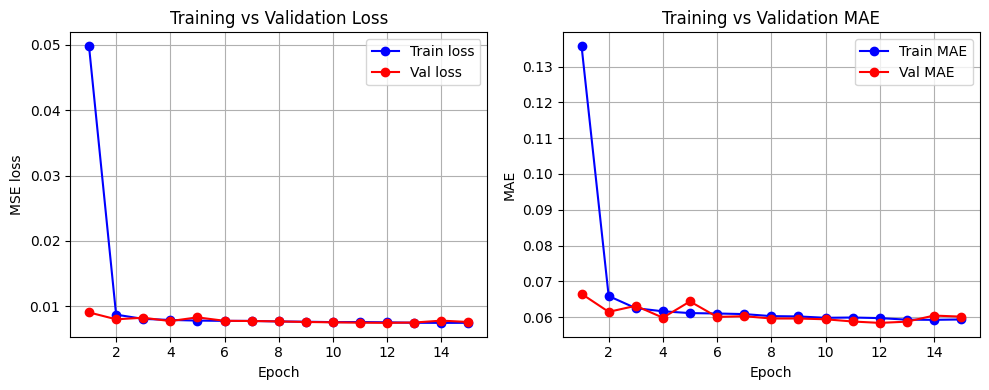

In [9]:
def plot_training_curves(history_obj):
    hist = history_obj.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(10, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, hist["loss"], "b-o", label="Train loss")
    plt.plot(epochs_range, hist["val_loss"], "r-o", label="Val loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)

    # MAE
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, hist["mae"], "b-o", label="Train MAE")
    plt.plot(epochs_range, hist["val_mae"], "r-o", label="Val MAE")
    plt.xlabel("Epoch")
    plt.ylabel("MAE")
    plt.title("Training vs Validation MAE")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# TODO: Uncomment to visualize training curves
plot_training_curves(history)

In [ ]:
### TODO: Create a visualization that compares predicted and actual values.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step


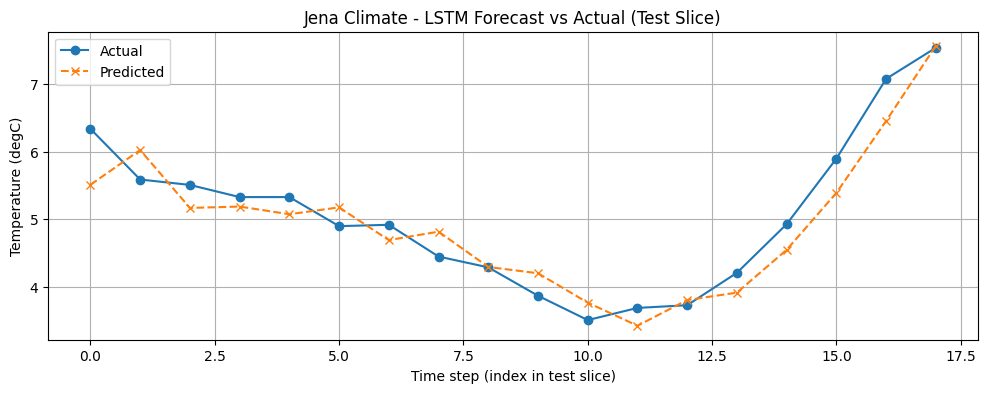

In [10]:
# TODO:Implement visualization
NUM_POINTS = 18  # TODO: adjust number of points to visualize

X_vis = X_test[:NUM_POINTS]
y_true = y_test[:NUM_POINTS]

y_pred = model.predict(X_vis).flatten()

# Convert back to original scale
y_true_actual = y_true * std + mean
y_pred_actual = y_pred * std + mean

plt.figure(figsize=(12, 4))
plt.plot(y_true_actual, label="Actual", marker="o", linestyle="-")
plt.plot(y_pred_actual, label="Predicted", marker="x", linestyle="--")
plt.xlabel("Time step (index in test slice)")
plt.ylabel("Temperature (degC)")
plt.title("Jena Climate - LSTM Forecast vs Actual (Test Slice)")
plt.legend()
plt.grid(True)
plt.show()

### TODO: Explain how you implemented the LSTM architecture.

#### To build and train the time-series forecasting model for the Jena Climate dataset, a model was created using TensorFlow and Keras. The model uses the previous 24 hours of data to predict the weather 1 hour ahead. It includes an LSTM layer with 32 units to learn patterns over time, followed by a Dense layer with 16 units and ReLU activation to process the information. The final layer produces the prediction. The model used the Adam optimizer with a learning rate of 0.001 and Mean Squared Error (MSE) to measure errors during training. It was trained for 15 epochs with a batch size of 64. When tested with new data, the model achieved a Test MSE of 0.0066 and a Test MAE of 0.0573. These results show that the model learned the data patterns and was able to make accurate predictions on data it had not seen before.